# COMP4328 Assignment 2 — GCE add-on only

Start a new **L4 GPU** runtime and **Run all**. This notebook trains only GCE: three datasets × ten splits = **30 new fits**. It does not rerun the completed eight-configuration suite. Running the training cells uses your Colab credits.

The old results remain read-only under `experiment_results_v2`. New results go to **`experiment_results_gce_v1`** in your new `Draft Assignment 2 COMP4328` folder. Only one active notebook should use that new output location.

Plain GCE uses **q=0.7**, fixed before these new test outcomes. The CNN, splits, initialisation seeds, preprocessing and base training budgets match the earlier study. Checkpoint selection minimises **GCE on noisy validation labels**; clean test labels are evaluation-only. This criterion is explicitly different from CE/forward validation in the old methods.

In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
from pathlib import Path
import hashlib
import json
import shutil
import subprocess
import sys
import zipfile
import torch
if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime before continuing; use L4 to match the earlier experiment")
print("GPU:", torch.cuda.get_device_name(0), "PyTorch:", torch.__version__)
from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = Path("/content/drive/MyDrive/Draft Assignment 2 COMP4328")
if not DRIVE_DIR.is_dir():
    raise FileNotFoundError("Check the mounted account: the authorised new folder is missing")
ROOT = Path("/content/comp4328_gce_addon_v1")
ROOT.mkdir(exist_ok=True)
BACKUP = DRIVE_DIR / "experiment_results_gce_v1"
BACKUP.mkdir(exist_ok=True)

GPU: NVIDIA L4 PyTorch: 2.11.0+cu130
Mounted at /content/drive


## 1. Copy verified source and datasets into runtime storage

The new source ZIP includes the original verified core unchanged plus the independent GCE runner and tests. No old training command is invoked. Datasets remain separate from the source submission ZIP.

In [2]:
CODE_ARCHIVE = DRIVE_DIR / "assignment2_code_with_gce_v1.zip"
CODE_SHA256 = "44237c3f039d13e085b4487d2735a452926ca95ed536665ec3e40b1f037b7e2f"
DATA_SHA256 = "e2ce73884b721359571c1f80f6e2d3510b1d21d57b8a1d6d1286f487657b7aff"
def sha256(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()
def checked_copy(source, destination, expected):
    if sha256(source) != expected:
        raise ValueError(f"Unexpected input contents: {source.name}")
    shutil.copyfile(source, destination)
    if sha256(destination) != expected:
        raise OSError("Runtime input copy checksum mismatch")
local_code = ROOT / "source.zip"
checked_copy(CODE_ARCHIVE, local_code, CODE_SHA256)
with zipfile.ZipFile(local_code) as archive:
    for member in archive.namelist():
        target = (ROOT / member).resolve()
        if target != ROOT and ROOT not in target.parents:
            raise ValueError("Unsafe ZIP path")
    archive.extractall(ROOT)
local_data = ROOT / "datasets.zip"
checked_copy(DRIVE_DIR / "datasets.zip", local_data, DATA_SHA256)
expected = {"FashionMNIST0.3.npz", "FashionMNIST0.6.npz", "CIFAR.npz"}
found = set()
with zipfile.ZipFile(local_data) as archive:
    for name in archive.namelist():
        basename = Path(name).name
        if basename in expected:
            if basename in found:
                raise ValueError("Duplicate dataset")
            with archive.open(name) as source, (ROOT / "data" / basename).open("wb") as destination:
                shutil.copyfileobj(source, destination)
            found.add(basename)
if found != expected:
    raise ValueError("Dataset archive is incomplete")
sys.path.insert(0, str(ROOT))
from algorithm.main import choose_device
choose_device("cuda")
print("Source and all datasets validated")

Source and all datasets validated


## 2. Read completed results for paired comparison

Only JSON summaries, manifests and split descriptions are copied. The old model checkpoints are not downloaded. The old final audit must have passed; GCE will check matching dataset hashes, source, split indices, preprocessing and base budgets. Environment differences will be recorded for disclosure.

In [3]:
PREVIOUS = DRIVE_DIR / "experiment_results_v2"
old_audit = json.loads((PREVIOUS / "checks" / "final_audit.json").read_text())
if (not old_audit.get("passed") or len(old_audit.get("experiments", [])) != 8
        or not all(e["complete"] and e["reportable"] and e["runs"] == 10 and e["test_predictions_replayed"] for e in old_audit["experiments"])):
    raise ValueError("The original full experiment audit is incomplete")
REFERENCE = ROOT / "baseline_reference"
REFERENCE.mkdir(exist_ok=True)
count = 0
for old in sorted((PREVIOUS / "final_v1").iterdir()):
    if not old.is_dir() or not (old / "results.json").is_file():
        continue
    destination = REFERENCE / old.name
    destination.mkdir(exist_ok=True)
    for name in ("results.json", "manifest.json"):
        shutil.copyfile(old / name, destination / name)
    splits = list(old.glob("run_*/split.json"))
    if len(splits) != 10:
        raise ValueError(f"Incomplete old split metadata: {old.name}")
    for path in splits:
        target = destination / path.parent.name / "split.json"
        target.parent.mkdir(exist_ok=True)
        shutil.copyfile(path, target)
    count += 1
if count != 8:
    raise ValueError("Expected all eight completed reference configurations")
from gce_addon import load_references
load_references(REFERENCE)
print("Read eight completed result sets; no old training was run")

Read eight completed result sets; no old training was run


## 3. Tests and backup helpers

Each GCE epoch saves model, optimiser, RNG states and the selected checkpoint. Backups occur about every 20 seconds plus on exit. Recovery starts at the last backed-up completed epoch; an unfinished epoch may repeat. Code/configuration/environment changes require a new output directory. A fresh runtime restores backups automatically.

In [4]:
subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", str(ROOT), "-p", "test_gce_addon.py", "-v"], check=True, cwd=ROOT)
from runtime_backup import sync_tree, run_with_backup

def restore(local, remote):
    if remote.is_dir() and not local.exists():
        sync_tree(remote, local)
    if local.exists():
        for lock in local.rglob(".running.lock"):
            pid = int(lock.read_text().strip())
            try:
                os.kill(pid, 0)
            except ProcessLookupError:
                lock.unlink()
            else:
                raise RuntimeError(f"Runner PID {pid} may be active; do not start another")

def launch_gce(local, remote, smoke=False):
    restore(local, remote)
    command = [sys.executable, "-u", str(ROOT / "gce_addon.py"), "train", "--data-dir", str(ROOT / "data"),
               "--output", str(local), "--device", "cuda", "--q", "0.7"]
    if smoke:
        command += ["--smoke", "--runs", "2", "--epochs", "2", "--sample-limit", "600", "--test-limit", "300"]
    else:
        command += ["--reference-dir", str(REFERENCE)]
    if (local / "manifest.json").is_file():
        command.append("--resume")
    run_with_backup(command, local, remote, CODE_ARCHIVE, interval=20)

def audit(local):
    subprocess.run([sys.executable, str(ROOT / "gce_addon.py"), "verify", "--data-dir", str(ROOT / "data"),
                    "--output", str(local), "--device", "cuda"], check=True)

## 4. Small GCE-only GPU check

Six short fits test the three datasets. These diagnostic results are not reportable. This cell does not launch any original CE/forward/reweight/revision training.

In [5]:
SMOKE = ROOT / "experiments" / "gce_smoke_v1"
launch_gce(SMOKE, BACKUP / "smoke_v1", smoke=True)
audit(SMOKE)
sync_tree(SMOKE, BACKUP / "smoke_v1")
print("GCE GPU smoke check and checkpoint replay passed")

Backup: 2 updated files
GCE GPU smoke check and checkpoint replay passed


## 5. Train only the 30 new GCE models

The fixed budgets are 20 epochs for each Fashion fit and 40 for each CIFAR fit. Validation uses only noisy labels. Do not change q after viewing test scores. Set `RUN_GCE=False` for checks only. Earlier model training is never invoked by this notebook.

In [6]:
RUN_GCE = True
FINAL = ROOT / "experiments" / "gce_final_v1"
if RUN_GCE:
    launch_gce(FINAL, BACKUP / "final_v1")
    print("All 30 new GCE fits completed")
else:
    print("Final GCE training skipped")

Backup: 1 updated files
Backup: 7 updated files
Backup: 10 updated files
Backup: 6 updated files
Backup: 10 updated files
Backup: 10 updated files
Backup: 6 updated files
Backup: 11 updated files
Backup: 10 updated files
Backup: 8 updated files
Backup: 7 updated files
Backup: 10 updated files
Backup: 9 updated files
Backup: 1 updated files
Backup: 6 updated files
Backup: 6 updated files
Backup: 1 updated files
Backup: 6 updated files
Backup: 6 updated files
Backup: 1 updated files
Backup: 6 updated files
Backup: 6 updated files
Backup: 1 updated files
Backup: 6 updated files
Backup: 6 updated files
Backup: 1 updated files
Backup: 6 updated files
All 30 new GCE fits completed


## 6. Replay GCE scores and generate combined comparisons

Each original configuration is compared to GCE using its same split seeds. GCE's ten results per dataset are reused in the given/estimated-T table rows; those are not additional independent GCE fits. The combined table explicitly shows extra epochs used by the original refinement methods. Check `comparison_environment.json` before making claims about exact hardware/software matching.

Verified fashion0.3: 10 GCE checkpoints
Verified fashion0.6: 10 GCE checkpoints
Verified cifar: 10 GCE checkpoints


# Completed baseline experiments plus GCE

GCE uses q=0.7, fixed before its test outcomes. No old model was retrained.
Mean ± sample SD across the same ten splits. Refinement methods receive extra epochs, shown separately.

| Experiment | Method | Accuracy (%) | Base + extra epochs |
|---|---|---:|---:|
| fashion0.3_estimated_argmax | ce | 96.71 ± 1.40 | 20 + 0 |
| fashion0.3_estimated_argmax | forward | 96.81 ± 1.54 | 20 + 0 |
| fashion0.3_estimated_argmax | reweight | 96.25 ± 1.65 | 20 + 0 |
| fashion0.3_estimated_argmax | continued | 96.91 ± 0.74 | 20 + 10 |
| fashion0.3_estimated_argmax | continued_full | 96.34 ± 1.70 | 20 + 10 |
| fashion0.3_estimated_argmax | trevision | 96.36 ± 1.72 | 20 + 10 |
| fashion0.3_estimated_argmax | gce | 97.91 ± 0.44 | 20 + 0 |
| fashion0.3_estimated_trimmed | ce | 96.71 ± 1.40 | 20 + 0 |
| fashion0.3_estimated_trimmed | forward | 98.84 ± 0.17 | 20 + 0 |
| fashion0.3_estimated_trimmed | reweight | 98.24 ± 0.32 | 20 + 0 |
| fashion0.3_estimated_trimmed | continued | 98.34 ± 0.32 | 20 + 10 |
| fashion0.3_estimated_trimmed | continued_full | 98.63 ± 0.36 | 20 + 10 |
| fashion0.3_estimated_trimmed | trevision | 98.69 ± 0.15 | 20 + 10 |
| fashion0.3_estimated_trimmed | gce | 97.91 ± 0.44 | 20 + 0 |
| fashion0.3_given_trimmed | ce | 96.71 ± 1.40 | 20 + 0 |
| fashion0.3_given_trimmed | forward | 99.00 ± 0.22 | 20 + 0 |
| fashion0.3_given_trimmed | reweight | 98.61 ± 0.16 | 20 + 0 |
| fashion0.3_given_trimmed | continued | 98.80 ± 0.27 | 20 + 10 |
| fashion0.3_given_trimmed | continued_full | 98.86 ± 0.13 | 20 + 10 |
| fashion0.3_given_trimmed | trevision | 98.86 ± 0.15 | 20 + 10 |
| fashion0.3_given_trimmed | gce | 97.91 ± 0.44 | 20 + 0 |
| fashion0.6_estimated_argmax | ce | 88.64 ± 2.68 | 20 + 0 |
| fashion0.6_estimated_argmax | forward | 81.52 ± 6.74 | 20 + 0 |
| fashion0.6_estimated_argmax | reweight | 82.65 ± 8.70 | 20 + 0 |
| fashion0.6_estimated_argmax | continued | 82.49 ± 6.38 | 20 + 10 |
| fashion0.6_estimated_argmax | continued_full | 82.65 ± 8.70 | 20 + 10 |
| fashion0.6_estimated_argmax | trevision | 82.65 ± 8.70 | 20 + 10 |
| fashion0.6_estimated_argmax | gce | 89.98 ± 5.99 | 20 + 0 |
| fashion0.6_estimated_trimmed | ce | 88.64 ± 2.68 | 20 + 0 |
| fashion0.6_estimated_trimmed | forward | 88.30 ± 8.45 | 20 + 0 |
| fashion0.6_estimated_trimmed | reweight | 90.33 ± 5.51 | 20 + 0 |
| fashion0.6_estimated_trimmed | continued | 90.00 ± 5.76 | 20 + 10 |
| fashion0.6_estimated_trimmed | continued_full | 91.71 ± 6.11 | 20 + 10 |
| fashion0.6_estimated_trimmed | trevision | 92.23 ± 6.31 | 20 + 10 |
| fashion0.6_estimated_trimmed | gce | 89.98 ± 5.99 | 20 + 0 |
| fashion0.6_given_trimmed | ce | 88.64 ± 2.68 | 20 + 0 |
| fashion0.6_given_trimmed | forward | 91.76 ± 3.75 | 20 + 0 |
| fashion0.6_given_trimmed | reweight | 91.98 ± 3.29 | 20 + 0 |
| fashion0.6_given_trimmed | continued | 91.78 ± 4.19 | 20 + 10 |
| fashion0.6_given_trimmed | continued_full | 95.82 ± 1.20 | 20 + 10 |
| fashion0.6_given_trimmed | trevision | 95.74 ± 0.98 | 20 + 10 |
| fashion0.6_given_trimmed | gce | 89.98 ± 5.99 | 20 + 0 |
| cifar_estimated_argmax | ce | 59.91 ± 4.77 | 40 + 0 |
| cifar_estimated_argmax | forward | 63.53 ± 4.90 | 40 + 0 |
| cifar_estimated_argmax | reweight | 62.31 ± 4.16 | 40 + 0 |
| cifar_estimated_argmax | continued | 62.88 ± 4.23 | 40 + 20 |
| cifar_estimated_argmax | continued_full | 62.31 ± 4.16 | 40 + 20 |
| cifar_estimated_argmax | trevision | 62.31 ± 4.16 | 40 + 20 |
| cifar_estimated_argmax | gce | 59.88 ± 3.70 | 40 + 0 |
| cifar_estimated_trimmed | ce | 59.91 ± 4.77 | 40 + 0 |
| cifar_estimated_trimmed | forward | 69.56 ± 1.98 | 40 + 0 |
| cifar_estimated_trimmed | reweight | 67.35 ± 4.58 | 40 + 0 |
| cifar_estimated_trimmed | continued | 67.58 ± 1.79 | 40 + 20 |
| cifar_estimated_trimmed | continued_full | 67.35 ± 4.58 | 40 + 20 |
| cifar_estimated_trimmed | trevision | 67.35 ± 4.58 | 40 + 20 |
| cifar_estimated_trimmed | gce | 59.88 ± 3.70 | 40 + 0 |


Environment differences: [
  {
    "experiment": "fashion0.3_estimated_argmax",
    "changed_environment_fields": []
  },
  {
    "experiment": "fashion0.3_estimated_trimmed",
    "changed_environment_fields": []
  },
  {
    "experiment": "fashion0.3_given_trimmed",
    "changed_environment_fields": []
  },
  {
    "experiment": "fashion0.6_estimated_argmax",
    "changed_environment_fields": []
  },
  {
    "experiment": "fashion0.6_estimated_trimmed",
    "changed_environment_fields": []
  },
  {
    "experiment": "fashion0.6_given_trimmed",
    "changed_environment_fields": []
  },
  {
    "experiment": "cifar_estimated_argmax",
    "changed_environment_fields": []
  },
  {
    "experiment": "cifar_estimated_trimmed",
    "changed_environment_fields": []
  }
]



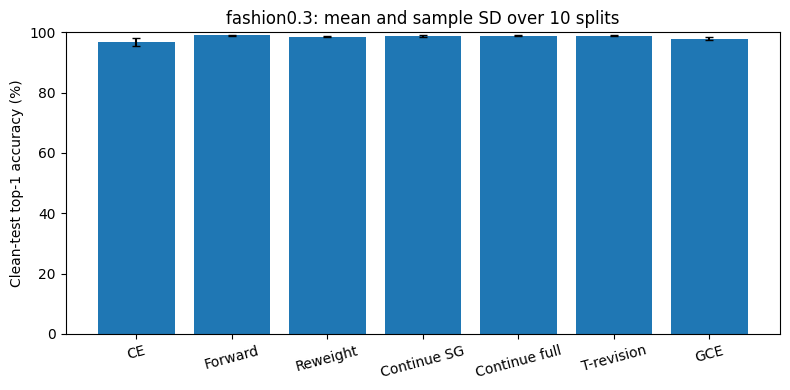

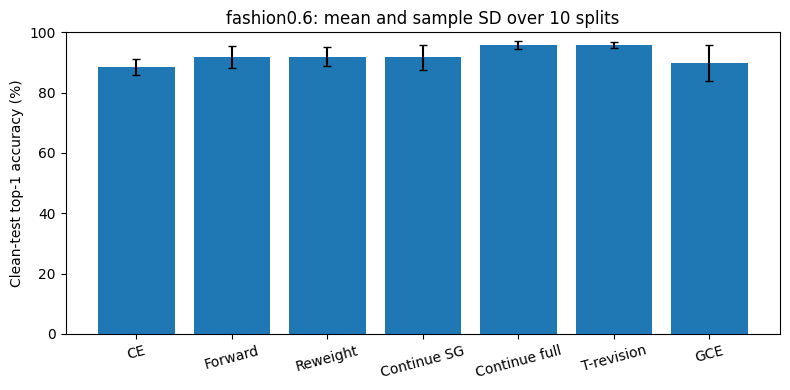

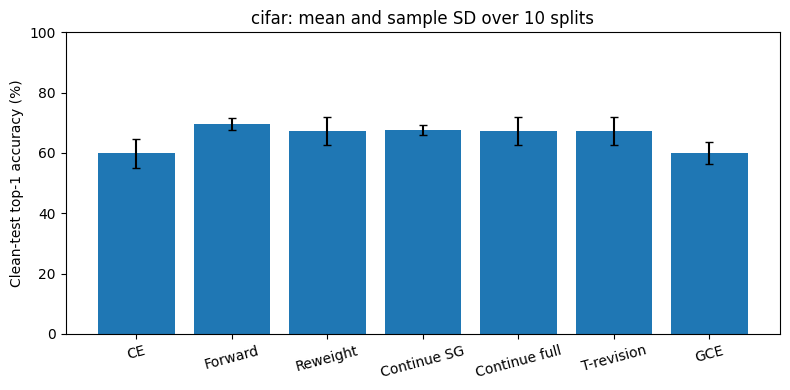

Done: all 30 GCE checkpoints replayed and new comparisons backed up to /content/drive/MyDrive/Draft Assignment 2 COMP4328/experiment_results_gce_v1


In [13]:
if RUN_GCE:
    audit(FINAL)
    subprocess.run([sys.executable, str(ROOT / "gce_addon.py"), "export", "--output", str(FINAL),
                    "--reference-dir", str(REFERENCE)], check=True)
    sync_tree(FINAL, BACKUP / "final_v1")
    from IPython.display import Markdown, display
    display(Markdown((FINAL / "analysis" / "comparison.md").read_text()))
    print("Environment differences:", (FINAL / "analysis" / "comparison_environment.json").read_text())
    import csv, importlib.util
    if importlib.util.find_spec("matplotlib") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "matplotlib>=3.8,<4"], check=True)
    import matplotlib.pyplot as plt
    from gce_addon import PRIMARY
    with (FINAL / "analysis" / "combined_accuracy.csv").open() as stream:
        rows = list(csv.DictReader(stream))
    labels = {"ce":"CE", "forward":"Forward", "reweight":"Reweight", "continued":"Continue SG", "continued_full":"Continue full", "trevision":"T-revision", "gce":"GCE"}
    for dataset, experiment in PRIMARY.items():
        selected = [r for r in rows if r["experiment"] == experiment]
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.bar([labels[r["method"]] for r in selected], [float(r["mean"]) for r in selected],
               yerr=[float(r["std"]) for r in selected], capsize=3)
        ax.set(ylabel="Clean-test top-1 accuracy (%)", ylim=(0,100), title=f"{dataset}: mean and sample SD over 10 splits")
        ax.tick_params(axis="x", labelrotation=15)
        fig.tight_layout()
        fig.savefig(FINAL / "analysis" / f"{dataset}_with_gce.pdf")
        plt.show()
        plt.close(fig)
    sync_tree(FINAL, BACKUP / "final_v1")
    print("Done: all 30 GCE checkpoints replayed and new comparisons backed up to", BACKUP)

In [9]:
#Ignore this Just debugging, found our that verification was not taking the gpu train settings
r = subprocess.run(
    [sys.executable, str(ROOT / "gce_addon.py"), "verify",
     "--data-dir", str(ROOT / "data"), "--output", str(FINAL),
     "--device", "cuda"],
    capture_output=True, text=True
)
print(r.stdout)
print(r.stderr)

Verified fashion0.3: 10 GCE checkpoints

Traceback (most recent call last):
  File "/content/comp4328_gce_addon_v1/gce_addon.py", line 385, in <module>
    main()
    ~~~~^^
  File "/content/comp4328_gce_addon_v1/gce_addon.py", line 379, in main
    verify(args)
    ~~~~~~^^^^^^
  File "/content/comp4328_gce_addon_v1/gce_addon.py", line 288, in verify
    best = verify_run(directory, record, signature, tensors, split, replay=True)
  File "/content/comp4328_gce_addon_v1/gce_addon.py", line 258, in verify_run
    np.testing.assert_allclose(accuracy(model, tensors["x_test"], tensors["y_test"]), record["accuracy"], atol=1e-5, rtol=0)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/numpy/testing/_private/utils.py", line 1768, in assert_allclose
    assert_array_compare(compare, actual, desired, err_msg=str(err_msg),
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^

In [12]:
#restores matching precision and deterministic settings without changing checkpoints or relaxing the accuracy check
from types import SimpleNamespace
from pathlib import Path
from algorithm.engine import seed_everything
import gce_addon

def audit(local):
    seed_everything(0, deterministic=True)
    return gce_addon.verify(SimpleNamespace(
        output=Path(local),
        data_dir=ROOT / "data",
        device="cuda",
        threads=4,
    ))

## Report and submission

Use `README_GCE.md` in the source package for the formula, original paper and exact protocol. Explain the matrix-independent comparison and any weak results. Better test accuracy is not guaranteed. Do not treat reuse of GCE in eight context rows as 80 independent GCE runs.

The combined source ZIP contains an empty `data/` folder and no datasets or results. Rename that ZIP using the required group/student-ID naming rule for submission. The original results/figures remain in their earlier Drive backup; new GCE artefacts are in `experiment_results_gce_v1`.

Local CPU/GPU tests and epoch-recovery checks were completed before this notebook was prepared. Actual Colab compatibility and final GCE scores are established by running the smoke, final training and audit cells above.